In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt #visualization
import seaborn as sns #better/easier stastical graphs
import joblib #store the trained model
import os #acces the files

In [ ]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving personal_finance_dummy_dataset_1200.csv to personal_finance_dummy_dataset_1200.csv
User uploaded file "personal_finance_dummy_dataset_1200.csv" with length 88978 bytes


In [ ]:
df = pd.read_csv('/content/personal_finance_dummy_dataset_1200.csv')

In [ ]:
display(df.head())

,transaction_id,user_id,date,transaction_type,category,amount,payment_mode,location,notes
0,T100001,U032,2025-10-09,Expense,Food,12199,Debit Card,Mumbai,Snacks
1,T100002,U004,2025-02-02,Income,Salary,60302,UPI,Pune,Monthly salary
2,T100003,U092,2025-07-23,Expense,Food,9245,Bank Transfer,Ahmedabad,Dinner
3,T100004,U090,2025-06-13,Income,Investment,5851,Cash,Bangalore,Dividend
4,T100005,U049,2025-04-05,Income,Investment,18396,UPI,Bangalore,Dividend


In [ ]:
# Check data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   transaction_id    1200 non-null   object
 1   user_id           1200 non-null   object
 2   date              1200 non-null   object
 3   transaction_type  1200 non-null   object
 4   category          1200 non-null   object
 5   amount            1200 non-null   int64 
 6   payment_mode      1200 non-null   object
 7   location          1200 non-null   object
 8   notes             1200 non-null   object
dtypes: int64(1), object(8)
memory usage: 84.5+ KB


In [ ]:
# Check for missing values
df.isnull().sum()

,0
transaction_id,0
user_id,0
date,0
transaction_type,0
category,0
amount,0
payment_mode,0
location,0
notes,0


In [ ]:
# Convert 'date' column to datetime objects
df['date'] = pd.to_datetime(df['date'])

# Extract time-based features
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek # Monday=0, Sunday=6

# Display the DataFrame with new features and check dtypes
display(df.head())
df.info()

,transaction_id,user_id,date,transaction_type,category,amount,payment_mode,location,notes,year,month,day_of_week
0,T100001,U032,2025-10-09,Expense,Food,12199,Debit Card,Mumbai,Snacks,2025,10,3
1,T100002,U004,2025-02-02,Income,Salary,60302,UPI,Pune,Monthly salary,2025,2,6
2,T100003,U092,2025-07-23,Expense,Food,9245,Bank Transfer,Ahmedabad,Dinner,2025,7,2
3,T100004,U090,2025-06-13,Income,Investment,5851,Cash,Bangalore,Dividend,2025,6,4
4,T100005,U049,2025-04-05,Income,Investment,18396,UPI,Bangalore,Dividend,2025,4,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    1200 non-null   object        
 1   user_id           1200 non-null   object        
 2   date              1200 non-null   datetime64[ns]
 3   transaction_type  1200 non-null   object        
 4   category          1200 non-null   object        
 5   amount            1200 non-null   int64         
 6   payment_mode      1200 non-null   object        
 7   location          1200 non-null   object        
 8   notes             1200 non-null   object        
 9   year              1200 non-null   int32         
 10  month             1200 non-null   int32         
 11  day_of_week       1200 non-null   int32         
dtypes: datetime64[ns](1), int32(3), int64(1), object(7)
memory usage: 98.6+ KB


In [ ]:
# Drop identifier columns that are not directly used as features for a general model
df = df.drop(columns=['transaction_id', 'user_id'])

# Inspect unique values and counts for categorical columns
print("Unique values for 'transaction_type':", df['transaction_type'].unique())
print("Count of unique 'transaction_type' values:", df['transaction_type'].nunique())

print("\nUnique values for 'category':", df['category'].unique())
print("Count of unique 'category' values:", df['category'].nunique())

print("\nUnique values for 'payment_mode':", df['payment_mode'].unique())
print("Count of unique 'payment_mode' values:", df['payment_mode'].nunique())

print("\nUnique values for 'location':", df['location'].unique())
print("Count of unique 'location' values:", df['location'].nunique())

print("\nUnique values for 'notes':", df['notes'].unique())
print("Count of unique 'notes' values:", df['notes'].nunique())

Unique values for 'transaction_type': ['Expense' 'Income']
Count of unique 'transaction_type' values: 2

Unique values for 'category': ['Food' 'Salary' 'Investment' 'Groceries' 'Bills' 'Entertainment' 'Fuel'
 'Education' 'Travel' 'Freelance' 'Rent' 'Bonus' 'Shopping' 'Healthcare']
Count of unique 'category' values: 14

Unique values for 'payment_mode': ['Debit Card' 'UPI' 'Bank Transfer' 'Cash' 'Net Banking' 'Credit Card']
Count of unique 'payment_mode' values: 6

Unique values for 'location': ['Mumbai' 'Pune' 'Ahmedabad' 'Bangalore' 'Chennai' 'Delhi' 'Hyderabad'
 'Jaipur' 'Kolkata' 'Bhubaneswar']
Count of unique 'location' values: 10

Unique values for 'notes': ['Snacks' 'Monthly salary' 'Dinner' 'Dividend' 'Lunch' 'Supermarket'
 'Internet bill' 'Movie' 'Petrol' 'Course fee' 'Cab' 'Client payment'
 'Electricity bill' 'Monthly rent' 'Performance bonus' 'Electronics'
 'Medicine' 'Clothes']
Count of unique 'notes' values: 18


In [ ]:

df = df.drop(columns=['date', 'notes', 'category'])

# Identify categorical columns for one-hot encoding
categorical_cols = ['transaction_type', 'payment_mode', 'location']

# Apply one-hot encoding
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Display the first few rows of the encoded DataFrame and its info to see the new shape
display(df_encoded.head())
df_encoded.info()


,amount,year,month,day_of_week,transaction_type_Income,payment_mode_Cash,payment_mode_Credit Card,payment_mode_Debit Card,payment_mode_Net Banking,payment_mode_UPI,location_Bangalore,location_Bhubaneswar,location_Chennai,location_Delhi,location_Hyderabad,location_Jaipur,location_Kolkata,location_Mumbai,location_Pune
0,12199,2025,10,3,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False
1,60302,2025,2,6,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True
2,9245,2025,7,2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,5851,2025,6,4,True,True,False,False,False,False,True,False,False,False,False,False,False,False,False
4,18396,2025,4,5,True,False,False,False,False,True,True,False,False,False,False,False,False,False,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   amount                    1200 non-null   int64
 1   year                      1200 non-null   int32
 2   month                     1200 non-null   int32
 3   day_of_week               1200 non-null   int32
 4   transaction_type_Income   1200 non-null   bool 
 5   payment_mode_Cash         1200 non-null   bool 
 6   payment_mode_Credit Card  1200 non-null   bool 
 7   payment_mode_Debit Card   1200 non-null   bool 
 8   payment_mode_Net Banking  1200 non-null   bool 
 9   payment_mode_UPI          1200 non-null   bool 
 10  location_Bangalore        1200 non-null   bool 
 11  location_Bhubaneswar      1200 non-null   bool 
 12  location_Chennai          1200 non-null   bool 
 13  location_Delhi            1200 non-null   bool 
 14  location_Hyderabad        1200 non-null 

In [ ]:
from sklearn.model_selection import train_test_split

# Define features X and target y
X = df_encoded.drop(columns=['transaction_type_Income'])
y = df_encoded['transaction_type_Income']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (960, 18)
X_test shape: (240, 18)
y_train shape: (960,)
y_test shape: (240,)


In [ ]:
'''from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize and train the Logistic Regression model
model = LogisticRegression(random_state=42, solver='liblinear') # 'liblinear' handles L1/L2 penalties and is good for small datasets
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))'''

'from sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import accuracy_score, classification_report, confusion_matrix\n\n# Initialize and train the Logistic Regression model\nmodel = LogisticRegression(random_state=42, solver=\'liblinear\') # \'liblinear\' handles L1/L2 penalties and is good for small datasets\nmodel.fit(X_train, y_train)\n\n# Make predictions on the test set\ny_pred = model.predict(X_test)\n\n# Evaluate the model\nprint("Accuracy:", accuracy_score(y_test, y_pred))\nprint("\nClassification Report:\n", classification_report(y_test, y_pred))\nprint("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))'

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


X_train_cleaned = X_train
X_test_cleaned = X_test

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_cleaned, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test_cleaned)

# Evaluate the Random Forest model
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nRandom Forest Classification Report:\n", classification_report(y_test, y_pred_rf))
print("\nRandom Forest Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.9583333333333334

Random Forest Classification Report:
               precision    recall  f1-score   support

       False       0.95      1.00      0.97       172
        True       1.00      0.85      0.92        68

    accuracy                           0.96       240
   macro avg       0.97      0.93      0.95       240
weighted avg       0.96      0.96      0.96       240


Random Forest Confusion Matrix:
 [[172   0]
 [ 10  58]]


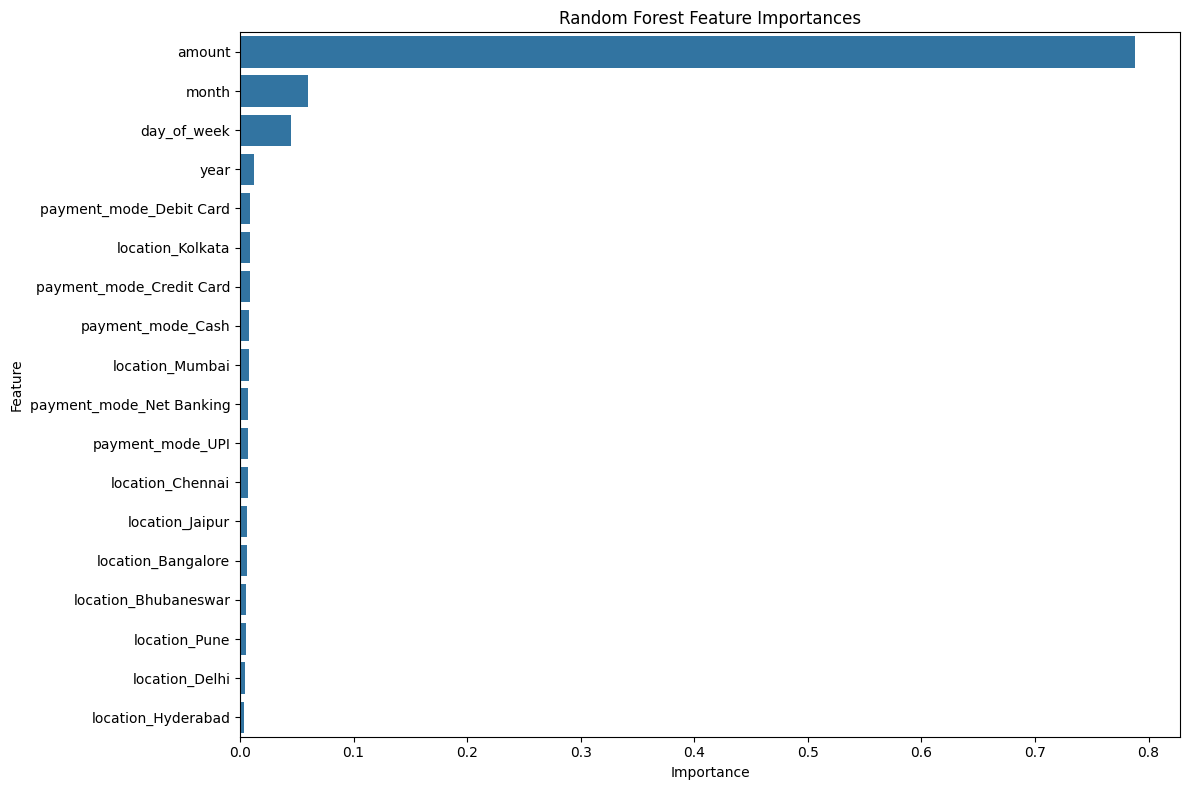

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importances from the trained Random Forest model
feature_importances = rf_model.feature_importances_

# Get feature names from the training data (should match the data used for training the model)
feature_names = X_train_cleaned.columns

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})

# Sort the features by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# Define the path to save the model
model_save_path = '/mnt/user-data/outputs/transaction_type_classifier.joblib'

# Create the directory if it doesn't exist
os.makedirs(os.path.dirname(model_save_path), exist_ok=True)

# Save the trained Random Forest model
joblib.dump(rf_model, model_save_path)

print(f"Random Forest model saved to {model_save_path}")

Random Forest model saved to /mnt/user-data/outputs/transaction_type_classifier.joblib


In [ ]:
import joblib
import pandas as pd

# Load the saved model
loaded_model = joblib.load(model_save_path)

print(f"Model loaded from: {model_save_path}")

# Example of making a prediction with the loaded model
# You would replace this with your actual new data
# For demonstration, let's take the first row from X_test_cleaned
sample_new_data = X_test_cleaned.iloc[[0]]

# Make a prediction
prediction = loaded_model.predict(sample_new_data)

print(f"\nSample new data for prediction:\n{sample_new_data}")
print(f"\nPredicted transaction type (True = Income, False = Expense): {prediction[0]}")

Model loaded from: /mnt/user-data/outputs/transaction_type_classifier.joblib

Sample new data for prediction:
      amount  year  month  day_of_week  payment_mode_Cash  \
1178    5631  2025      3            5              False   

      payment_mode_Credit Card  payment_mode_Debit Card  \
1178                     False                     True   

      payment_mode_Net Banking  payment_mode_UPI  location_Bangalore  \
1178                     False             False               False   

      location_Bhubaneswar  location_Chennai  location_Delhi  \
1178                 False              True           False   

      location_Hyderabad  location_Jaipur  location_Kolkata  location_Mumbai  \
1178               False            False             False            False   

      location_Pune  
1178          False  

Predicted transaction type (True = Income, False = Expense): False
